<a href="https://colab.research.google.com/github/magnogomes874/SSD-/blob/main/SSD%20Tarifa%20M%C3%A9dia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP - Análise e previsão de tarifas aéreas

Magno Gomes Sousa - 200031031

**Problema:** comparar tarifas aéreas domésticas históricas e avaliar se companhia, rota e ano permitem prever tarifas médias em períodos futuros.

**Usuário do SSD:** analista de tarifas aéreas. As previsões deste trabalho são médias por companhia e rota em novembro, não negritocotações de passagens individuais.



## 1 - Preparação do ambiente
O Colab costuma incluir `pandas`, `numpy`, `matplotlib` e `scikit-learn`. Testamos as bibliotecas primeiro; o **Gradio é instalado separadamente apenas na etapa do painel**. Isso facilita identificar problemas de conexão ou instalação.

In [1]:
import sys
from pathlib import Path
import io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn import __version__ as sklearn_version

print('✅ Python:',sys.version.split()[0])
print('✅ pandas:',pd.__version__,'| scikit-learn:',sklearn_version)
print('✅ Ambiente Python preparado.')
import sklearn
import platform
print('Reprodutibilidade: Python', platform.python_version(), '| scikit-learn', sklearn.__version__)
print('Nota: versões diferentes do scikit-learn podem alterar ligeiramente os resultados do Random Forest.')


✅ Python: 3.13.18
✅ pandas: 2.2.3 | scikit-learn: 1.6.1
✅ Ambiente Python preparado.
Reprodutibilidade: Python 3.13.18 | scikit-learn 1.6.1
Nota: versões diferentes do scikit-learn podem alterar ligeiramente os resultados do Random Forest.


## 2 - Importar e validar os dados

O arquivo carrega registros já agregados e ajustados pelo IPCA, não refaz a limpeza de 18,5 milhões de linhas nesta execução. Os arquivos anuais devem ser enviados **juntos** e **uma só vez**.

In [2]:
from google.colab import files

CAMINHO = Path('/content/anac_agregada_ml.csv')
ANOS_ESPERADOS = {2019, 2020, 2022, 2023, 2025}
CHAVE = ['ano','mes','empresa','origem','destino']
OBRIGATORIAS = set(CHAVE+['assentos','tarifa_media_real','tarifa_media_nominal'])

def carregar_arquivo(nome, conteudo):
    if nome.lower().endswith('.csv'):
        return pd.read_csv(io.BytesIO(conteudo))
    if not nome.lower().endswith('.zip'):
        raise ValueError(f'Formato não aceito: {nome}. Envie CSV ou ZIP.')
    with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
        csvs=[item for item in z.namelist()
              if item.lower().endswith('.csv') and not item.startswith('__MACOSX/')]
        if len(csvs)!=1:
            raise ValueError(f'{nome}: esperava um CSV dentro do ZIP, encontrei {len(csvs)}.')
        with z.open(csvs[0]) as arq:
            return pd.read_csv(arq)

def validar_base(df):
    faltantes=OBRIGATORIAS-set(df.columns)
    if faltantes: raise ValueError(f'Colunas ausentes: {sorted(faltantes)}')
    df=df.copy()
    for col in ['ano','mes','assentos','tarifa_media_real','tarifa_media_nominal']:
        df[col]=pd.to_numeric(df[col],errors='raise')
    if df[list(OBRIGATORIAS)].isna().any().any():
        raise ValueError('Há valores ausentes em campos obrigatórios.')
    if set(df['ano'].astype(int).unique())!=ANOS_ESPERADOS:
        raise ValueError(f'Anos inesperados/incompletos: {sorted(df.ano.unique())}')
    if not df['mes'].between(1,12).all(): raise ValueError('Mês inválido.')
    if not (df.assentos>0).all(): raise ValueError('Assentos devem ser positivos.')
    if not np.isfinite(df[['tarifa_media_real','tarifa_media_nominal']]).all().all():
        raise ValueError('Foram identificadas tarifas não finitas.')
    if df.duplicated(CHAVE).any():
        raise ValueError('Combinações duplicadas! Não envie o ZIP único junto dos ZIPs anuais.')
    return df

if CAMINHO.exists():
    print('📁 Utilizando arquivo já presente nesta sessão:', CAMINHO)
    print('Para substituir a base, exclua esse arquivo no painel lateral do Colab ou reinicie a sessão.')
    full=pd.read_csv(CAMINHO)
else:
    print('📤 Faça upload do ZIP único OU dos cinco ZIPs anuais de uma só vez.')
    enviados=files.upload()
    if not enviados: raise ValueError('Nenhum arquivo enviado.')
    partes=[]
    for nome,conteudo in enviados.items():
        parte=carregar_arquivo(nome,conteudo)
        partes.append(parte)
        print(f'  ✅ {nome}: {len(parte):,} grupos')
    full=pd.concat(partes,ignore_index=True)
    full=validar_base(full)
    full.to_csv(CAMINHO,index=False)

full=validar_base(full)
nov=full.loc[full.mes.eq(11)].copy().reset_index(drop=True)
if set(nov.ano.astype(int).unique())!=ANOS_ESPERADOS:
    raise ValueError('Novembro não está presente em todos os cinco anos.')
print(f'✅ Base validada: {len(full):,} grupos | Novembro: {len(nov):,} grupos')
display(nov.groupby('ano',as_index=False).agg(grupos=('empresa','size'),assentos=('assentos','sum')))

📤 Faça upload do ZIP único OU dos cinco ZIPs anuais de uma só vez.


Saving ANAC_2022.zip to ANAC_2022.zip
Saving ANAC_2023.zip to ANAC_2023.zip
Saving ANAC_2019.zip to ANAC_2019.zip
Saving ANAC_2020.zip to ANAC_2020.zip
Saving ANAC_2025.zip to ANAC_2025.zip
  ✅ ANAC_2022.zip: 134,849 grupos
  ✅ ANAC_2023.zip: 131,774 grupos
  ✅ ANAC_2019.zip: 132,262 grupos
  ✅ ANAC_2020.zip: 105,140 grupos
  ✅ ANAC_2025.zip: 10,396 grupos
✅ Base validada: 514,421 grupos | Novembro: 54,379 grupos


,ano,grupos,assentos
0,2019,11747,3986521
1,2020,9880,2714050
2,2022,11536,2456623
3,2023,10820,2451230
4,2025,10396,3648451


## 3 - Análise histórica e correção monetária
A tarifa real já está corrigida pelo IPCA para dezembro de 2025. Usamos a média **ponderada por assentos** para evitar dar peso igual a registros com diferentes volumes de vendas.

O gráfico nominal × real mostra por que valores de anos diferentes não devem ser comparados sem correção pela inflação. A associação entre pandemia e tarifa é **descritiva, não causal**.

,ano,nominal_R$,real_R$,assentos,variacao_real_vs_2019_%
0,2019,393.19,553.43,3986521,0.00
1,2020,387.81,523.30,2714050,-5.45
2,2022,635.06,730.71,2456623,32.03
3,2023,702.70,772.36,2451230,39.56
4,2025,607.92,609.93,3648451,10.21


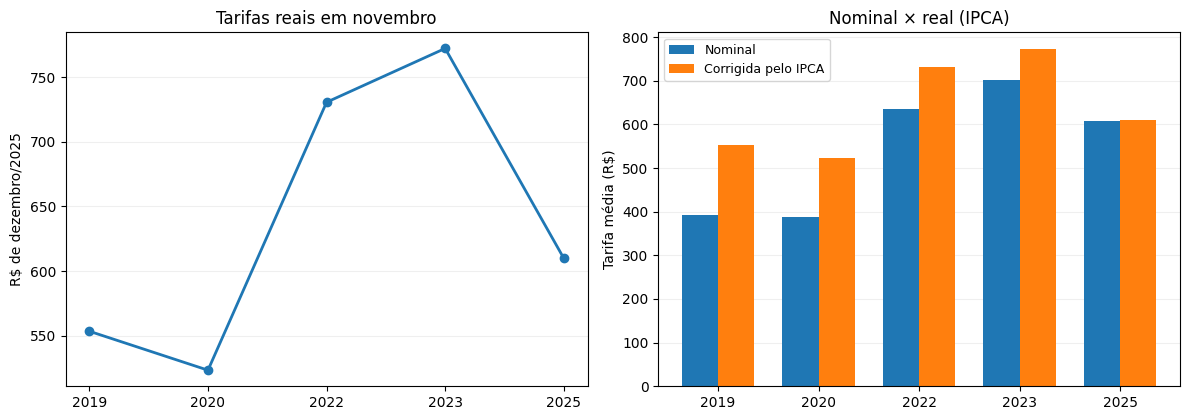

In [3]:
def media_ponderada(df,coluna):
    return float(np.average(df[coluna].to_numpy(dtype=float),weights=df.assentos.to_numpy(dtype=float)))

resumo=pd.DataFrame([
    {'ano':int(ano),'nominal_R$':media_ponderada(g,'tarifa_media_nominal'),
     'real_R$':media_ponderada(g,'tarifa_media_real'), 'assentos':int(g.assentos.sum())}
    for ano,g in nov.groupby('ano',sort=True)
])
ref2019=float(resumo.loc[resumo.ano.eq(2019),'real_R$'].iloc[0])
resumo['variacao_real_vs_2019_%']=100*(resumo['real_R$']/ref2019-1)
display(resumo.round(2))

fig,axs=plt.subplots(1,2,figsize=(12,4.3))
rotulos=resumo.ano.astype(str).to_numpy()
axs[0].plot(rotulos,resumo['real_R$'],marker='o',linewidth=2)
axs[0].set(title='Tarifas reais em novembro',ylabel='R$ de dezembro/2025')
x=np.arange(len(rotulos))
axs[1].bar(x-.18,resumo['nominal_R$'],width=.36,label='Nominal')
axs[1].bar(x+.18,resumo['real_R$'],width=.36,label='Corrigida pelo IPCA')
axs[1].set(xticks=x,xticklabels=rotulos,title='Nominal × real (IPCA)',ylabel='Tarifa média (R$)')
axs[1].legend(fontsize=9)
for ax in axs:
    ax.grid(axis='y',alpha=.2)
    ax.set_axisbelow(True)
fig.tight_layout();plt.show()

## 4 - Modelagem

- **Média histórica:** referência simples consegue prevê a média de treino ponderada pelos assentos.
- **Persistência por rota:** utiliza a tarifa do **último ano de treinamento** na mesma combinação companhia–origem–destino; se não houver rota, recorre à média da companhia ou à média global daquele ano.
- **Ridge:** regressão linear regularizada (`alpha=100`), capaz de avaliar efeitos de atributos sem permitir coeficientes excessivamente grandes.
- **Random Forest:** combina 70 árvores, identifica interações e relações não lineares, mas não garante menor erro em períodos futuros.

**One-Hot Encoding:** converte companhia, origem e destino em indicadores numéricos. **Ano:** testado com e sem a variável, para verificar o efeito da informação temporal. **Peso:** assentos comercializados tanto no treino quanto nas métricas.

**Validação temporal:** treinar com 2019/2020/2022 e testar em 2023; depois treinar incluindo 2023 e testar em 2025. O modelo **não vê as tarifas do ano de teste** no treinamento.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

ROTA=['empresa','origem','destino']
COM_ANO=['ano']+ROTA
ORDEM=['Média histórica','Persistência por rota',
       'Ridge (com ano)','Ridge (sem ano)',
       'Random Forest (com ano)','Random Forest (sem ano)']

def construir_modelo(tipo,com_ano):
    passos=[('categoria',OneHotEncoder(handle_unknown='ignore'),ROTA)]
    if com_ano:
        passos.append(('ano',StandardScaler(),['ano']))
    pre=ColumnTransformer(passos)
    if tipo=='Ridge': estimador=Ridge(alpha=100)
    else: estimador=RandomForestRegressor(
        n_estimators=70,max_depth=16,min_samples_leaf=4,
        max_features=.8,random_state=42,n_jobs=-1)
    return Pipeline([('prep',pre),('model',estimador)])

def calcular_metricas(teste,previsao):
    y=teste.tarifa_media_real.to_numpy()
    p=teste.assentos.to_numpy()
    return {'MAE_R$':mean_absolute_error(y,previsao,sample_weight=p),
            'RMSE_R$':np.sqrt(mean_squared_error(y,previsao,sample_weight=p)),
            'R2':r2_score(y,previsao,sample_weight=p)}

def persistencia(treino,teste):
    ultimo=treino.loc[treino.ano.eq(treino.ano.max())]
    por_rota=ultimo.set_index(ROTA).tarifa_media_real
    por_empresa={emp:media_ponderada(g,'tarifa_media_real') for emp,g in ultimo.groupby('empresa')}
    global_ultimo=media_ponderada(ultimo,'tarifa_media_real')
    previsoes=[]
    for emp,orig,dest in teste[ROTA].itertuples(index=False,name=None):
        chave=(emp,orig,dest)
        if chave in por_rota.index: valor=float(por_rota.loc[chave])
        else: valor=float(por_empresa.get(emp,global_ultimo))
        previsoes.append(valor)
    return np.array(previsoes,dtype=float)

def avaliar_periodo(ano,treino,teste):
    modelos={}; prevs={}; linhas=[]
    dummy=DummyRegressor(strategy='mean')
    dummy.fit(treino[COM_ANO],treino.tarifa_media_real,sample_weight=treino.assentos)
    modelos['Média histórica']=dummy
    prevs['Média histórica']=dummy.predict(teste[COM_ANO])
    prevs['Persistência por rota']=persistencia(treino,teste)
    for tipo in ['Ridge','Random Forest']:
        for com_ano in [True,False]:
            nome=f'{tipo} ({"com ano" if com_ano else "sem ano"})'
            attrs=COM_ANO if com_ano else ROTA
            mod=construir_modelo(tipo,com_ano)
            mod.fit(treino[attrs],treino.tarifa_media_real,model__sample_weight=treino.assentos)
            modelos[nome]=mod
            prevs[nome]=mod.predict(teste[attrs])
    for nome in ORDEM:
        linhas.append({'ano':ano,'modelo':nome,**calcular_metricas(teste,prevs[nome])})
    return pd.DataFrame(linhas),modelos,prevs

TREINOS={2023:nov.loc[nov.ano.isin([2019,2020,2022])],
        2025:nov.loc[nov.ano.isin([2019,2020,2022,2023])]}
TESTES={2023:nov.loc[nov.ano.eq(2023)],2025:nov.loc[nov.ano.eq(2025)]}

tabelas=[];modelos_treinados={};previsoes_periodos={}
for ano in (2023,2025):
    print(f'⏳ Treinando e avaliando modelos para novembro/{ano}...')
    m,mods,prevs=avaliar_periodo(ano,TREINOS[ano],TESTES[ano])
    tabelas.append(m);modelos_treinados[ano]=mods;previsoes_periodos[ano]=prevs
metricas=pd.concat(tabelas,ignore_index=True)
metricas['modelo']=pd.Categorical(metricas.modelo,categories=ORDEM,ordered=True)
metricas=metricas.sort_values(['ano','modelo']).reset_index(drop=True)
print('✅ Modelos treinados. Menor MAE e RMSE são melhores; maior R² é melhor.')
print('Random Forest: 70 árvores, random_state=42, max_depth=16, min_samples_leaf=4, max_features=0.8.')
print('Os resultados reproduzíveis nesta execução são a referência para atualizar o Short Paper; não altere os números manualmente.')
display(metricas.round(3))
metricas.to_csv('/content/metricas_modelos_consolidadas.csv',index=False)

⏳ Treinando e avaliando modelos para novembro/2023...
⏳ Treinando e avaliando modelos para novembro/2025...
✅ Modelos treinados. Menor MAE e RMSE são melhores; maior R² é melhor.
Random Forest: 70 árvores, random_state=42, max_depth=16, min_samples_leaf=4, max_features=0.8.
Os resultados reproduzíveis nesta execução são a referência para atualizar o Short Paper; não altere os números manualmente.


,ano,modelo,MAE_R$,RMSE_R$,R2
0,2023,Média histórica,260.242,381.399,-0.288
1,2023,Persistência por rota,229.965,336.237,-0.001
2,2023,Ridge (com ano),219.283,310.519,0.146
3,2023,Ridge (sem ano),241.488,350.065,-0.085
4,2023,Random Forest (com ano),223.704,321.159,0.087
5,2023,Random Forest (sem ano),243.434,354.374,-0.112
6,2025,Média histórica,195.430,270.476,-0.006
7,2025,Persistência por rota,293.395,445.250,-1.725
8,2025,Ridge (com ano),307.286,347.967,-0.664
9,2025,Ridge (sem ano),153.862,222.378,0.320


## 5 - Interpretar erros e capacidade de generalização
**MAE:** erro absoluto médio ponderado em reais.

**RMSE:** penaliza erros grandes.

**R²:** qualidade relativa à previsão constante da média do conjunto de teste (pode ser negativo).

Uma rota inédita é uma combinação companhia–origem–destino que não existia no treinamento.

🏆 Melhor configuração em cada período:


,ano,modelo,MAE_R$,RMSE_R$,R2
2,2023,Ridge (com ano),219.283,310.519,0.146
9,2025,Ridge (sem ano),153.862,222.378,0.320


Cobertura das combinações e erro do RF com ano:


,ano,grupo,combinacoes,assentos,MAE_RF_com_ano_R$,pct_assentos_ano
0,2023,Já observada,9474,2411553,222.473,98.381
1,2023,Inédita,1346,39677,298.559,1.619
2,2025,Já observada,9277,3628998,234.954,99.467
3,2025,Inédita,1119,19453,287.269,0.533


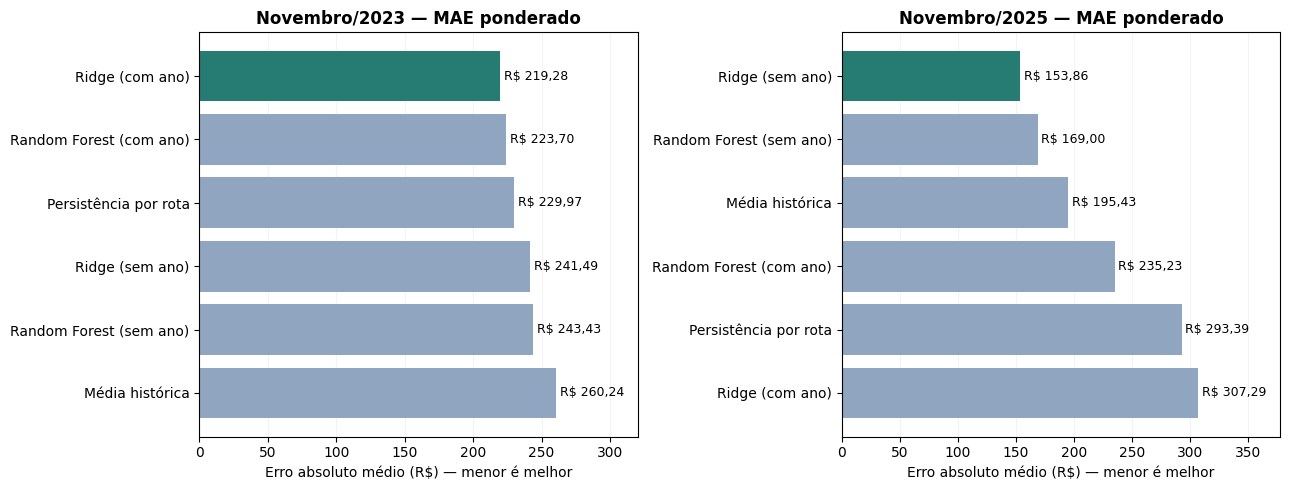

Conclusão: Ridge sem ano reduziu MAE em 21.3% vs. média histórica no teste 2025.
IMPORTANTE: compare os números gerados nesta sessão com a tabela do Short Paper, especialmente o Random Forest.


In [5]:
melhores=metricas.loc[
    metricas.groupby('ano',observed=True)['MAE_R$'].idxmin(),
    ['ano','modelo','MAE_R$','RMSE_R$','R2']
]
print('🏆 Melhor configuração em cada período:')
display(melhores.round(3))

diagnosticos=[]
for ano in (2023,2025):
    treino,teste=TREINOS[ano],TESTES[ano]
    existentes=set(map(tuple,treino[ROTA].itertuples(index=False,name=None)))
    ineditas=~teste[ROTA].apply(tuple,axis=1).isin(existentes)
    pred=previsoes_periodos[ano]['Random Forest (com ano)']
    for rotulo,mascara in [('Já observada',~ineditas.to_numpy()),('Inédita',ineditas.to_numpy())]:
        sub=teste.loc[mascara]
        if sub.empty: continue
        diagnosticos.append({'ano':ano,'grupo':rotulo,'combinacoes':len(sub),
            'assentos':int(sub.assentos.sum()),
            'MAE_RF_com_ano_R$':calcular_metricas(sub,np.asarray(pred)[mascara])['MAE_R$']})
diagnostico=pd.DataFrame(diagnosticos)
diagnostico['pct_assentos_ano']=100*diagnostico.assentos/diagnostico.groupby('ano').assentos.transform('sum')
print('Cobertura das combinações e erro do RF com ano:')
display(diagnostico.round(3))
diagnostico.to_csv('/content/diagnostico_combinacoes.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,ano in zip(axs,(2023,2025)):
    tab=metricas.loc[metricas.ano.eq(ano)].sort_values('MAE_R$')
    melhor=float(tab['MAE_R$'].min())
    cores=['#267b72' if np.isclose(valor,melhor) else '#90a5c0' for valor in tab['MAE_R$']]
    barras=ax.barh(tab.modelo.astype(str),tab['MAE_R$'],color=cores)
    ax.invert_yaxis()
    ax.set_title(f'Novembro/{ano} — MAE ponderado',fontweight='bold')
    ax.set_xlabel('Erro absoluto médio (R$) — menor é melhor')
    ax.set_xlim(0,max(tab['MAE_R$'])*1.23)
    ax.grid(axis='x',alpha=.14);ax.set_axisbelow(True)
    for b,v in zip(barras,tab['MAE_R$']):
        ax.text(b.get_width()+3,b.get_y()+b.get_height()/2,
                f'R$ {v:,.2f}'.replace(',','X').replace('.',',').replace('X','.'),
                va='center',fontsize=9)
fig.tight_layout();plt.show()

mae_ridge2025=float(metricas.loc[(metricas.ano==2025)&(metricas.modelo=='Ridge (sem ano)'),'MAE_R$'].iloc[0])
mae_base2025=float(metricas.loc[(metricas.ano==2025)&(metricas.modelo=='Média histórica'),'MAE_R$'].iloc[0])
print(f'Conclusão: Ridge sem ano reduziu MAE em {100*(mae_base2025-mae_ridge2025)/mae_base2025:.1f}% vs. média histórica no teste 2025.')
print('IMPORTANTE: compare os números gerados nesta sessão com a tabela do Short Paper, especialmente o Random Forest.')


## 6 - Painel do analista

O sistema reúne histórico das tarifas reais, comparação dos seis modelos e simulação de previsões em 2025.

A avaliação de 2025 foi feita com modelos treinados **apenas até 2023**, de modo que a tarifa observada em 2025 é apresentada exclusivamente para conferir o erro no teste.

**Usabilidade e validade:** os filtros oferecem apenas combinações existentes; indica-se se a rota já estava no treinamento. Os valores representam **tarifas médias históricas**, não cotações atuais.

As tabelas possuem cabeçalhos explícitos e a visualização inicial é carregada automaticamente.


In [6]:
# Execute esta célula somente depois que modelos e métricas estiverem prontos.
%pip -q install "gradio>=4,<7"
print('✅ Gradio instalado. Prossiga para a próxima célula.')

✅ Gradio instalado. Prossiga para a próxima célula.


In [9]:
import gradio as gr
from html import escape

# Todas as escolhas são fundamentadas em combinações observadas em novembro.
combinacoes=nov[ROTA].drop_duplicates()
EMPRESAS=sorted(combinacoes.empresa.astype(str).unique().tolist())
EMPRESA_INICIAL=EMPRESAS[0]
ROTAS_2025=TESTES[2025][ROTA].drop_duplicates()
EMPRESAS_2025=sorted(ROTAS_2025.empresa.astype(str).unique().tolist())
EMPRESA_2025_INICIAL=EMPRESAS_2025[0]
EXISTENTES_TREINO=set(TREINOS[2025][ROTA].itertuples(index=False,name=None))

def opcoes_aeroportos(empresa,origem='Todos'):
    sub=combinacoes[combinacoes.empresa.eq(empresa)]
    origens=['Todos']+sorted(sub.origem.unique().tolist())
    if origem not in origens: origem='Todos'
    dests=sub if origem=='Todos' else sub[sub.origem.eq(origem)]
    destinos=['Todos']+sorted(dests.destino.unique().tolist())
    return origens,destinos

def opcoes_rotas_2025(empresa):
    sub=ROTAS_2025[ROTAS_2025.empresa.eq(empresa)]
    return sorted((f'{origem} → {destino}' for origem,destino in sub[['origem','destino']].itertuples(index=False,name=None)))

def tabela_html(df,decimais=2):
    if df is None or df.empty:
        return '<p>Não foram encontrados registros para os filtros escolhidos.</p>'
    return '<div style="overflow-x:auto">'+df.to_html(index=False,escape=True,border=0,
            float_format=lambda x:f'{x:,.{decimais}f}'.replace(',','X').replace('.',',').replace('X','.'),
            classes='ssd-tab')+'</div>'

CSS="""
.ssd-tab {width:100%;border-collapse:collapse;font-size:14px}
.ssd-tab th {background:#e8edf4;color:#1b293c;padding:11px;text-align:left;white-space:nowrap}
.ssd-tab td {padding:9px 11px;border-bottom:1px solid #e7eaf0}
.ssd-tab tbody tr:nth-child(even) {background:#f7f9fc}
.ssd-intro {font-size:14px;color:#566477}
"""

def resumo_historico(empresa,origem,destino):
    dados=nov[nov.empresa.eq(empresa)]
    if origem!='Todos': dados=dados[dados.origem.eq(origem)]
    if destino!='Todos': dados=dados[dados.destino.eq(destino)]
    if dados.empty:
        return '<p>Sem dados para os filtros selecionados.</p>',None,'Nenhuma observação disponível.'
    linhas=[]
    for ano,g in dados.groupby('ano',sort=True):
        linhas.append({'Ano':int(ano),
            'Tarifa nominal (R$)':media_ponderada(g,'tarifa_media_nominal'),
            'Tarifa real (R$ dez/2025)':media_ponderada(g,'tarifa_media_real'),
            'Assentos':int(g.assentos.sum())})
    tab=pd.DataFrame(linhas)
    fig,ax=plt.subplots(figsize=(9,3.5))
    ax.plot(tab['Ano'].astype(str),tab['Tarifa real (R$ dez/2025)'],marker='o',linewidth=2,color='#267b72')
    ax.set(title='Evolução da tarifa real — anos observados',ylabel='Tarifa média real (R$)')
    ax.grid(axis='y',alpha=.2); fig.tight_layout()
    aviso=(f'{len(dados):,} grupos filtrados e {int(dados.assentos.sum()):,} assentos comercializados. '
           'As linhas ligam somente os anos disponíveis (não há interpolação).')
    return tabela_html(tab),fig,aviso

def ao_trocar_empresa_hist(empresa):
    origens,destinos=opcoes_aeroportos(empresa)
    return gr.update(choices=origens,value='Todos'),gr.update(choices=destinos,value='Todos')

def ao_trocar_origem_hist(empresa,origem):
    _,destinos=opcoes_aeroportos(empresa,origem)
    return gr.update(choices=destinos,value='Todos')

def comparar_modelos(ano):
    ano=int(ano)
    tab=metricas.loc[metricas.ano.eq(ano)].copy().sort_values('MAE_R$')
    vencedor=tab.iloc[0]
    tab['Modelo']=tab['modelo'].astype(str)
    tab=tab.rename(columns={'MAE_R$':'MAE (R$)','RMSE_R$':'RMSE (R$)','R2':'R²'})
    tab=tab[['Modelo','MAE (R$)','RMSE (R$)','R²']]
    info=diagnostico.loc[diagnostico.ano.eq(ano)].copy().rename(columns={
        'grupo':'Cobertura','combinacoes':'Combinações','assentos':'Assentos',
        'MAE_RF_com_ano_R$':'MAE RF com ano (R$)','pct_assentos_ano':'% dos assentos'})
    info=info[['Cobertura','Combinações','Assentos','% dos assentos','MAE RF com ano (R$)']]
    mensagem=f'**Menor MAE em {ano}: {vencedor["modelo"]} — R$ {vencedor["MAE_R$"]:.2f}.** O MAE e RMSE devem diminuir; R² deve aumentar.'
    return tabela_html(tab,3),tabela_html(info,3),mensagem

def ao_trocar_empresa_sim(empresa):
    rotas=opcoes_rotas_2025(empresa)
    return gr.update(choices=rotas,value=rotas[0] if rotas else None)

def simular_2025(empresa,rota):
    if not rota or rota not in opcoes_rotas_2025(empresa):
        return '<p>Selecione companhia e rota válidas.</p>','<p>Sem histórico.</p>','Selecione uma combinação válida.'
    origem,destino=rota.split(' → ',1)
    teste=TESTES[2025]
    linha=teste.loc[(teste.empresa==empresa)&(teste.origem==origem)&(teste.destino==destino)]
    if len(linha)!=1:
        return '<p>Combinação inválida.</p>','<p>Sem histórico.</p>','Combinação ausente ou duplicada no teste.'
    entrada=linha[COM_ANO].copy()
    observado=float(linha.tarifa_media_real.iloc[0])
    estimativas={}
    for nome in ORDEM:
        if nome=='Persistência por rota':
            estimativas[nome]=float(persistencia(TREINOS[2025],entrada)[0])
        else:
            attrs=ROTA if '(sem ano)' in nome else COM_ANO
            estimativas[nome]=float(modelos_treinados[2025][nome].predict(entrada[attrs])[0])
    linhas=[]
    for nome,valor in estimativas.items():
        mae=float(metricas.loc[(metricas.ano==2025)&(metricas.modelo==nome),'MAE_R$'].iloc[0])
        linhas.append({'Modelo':nome,'Tarifa prevista (R$)':valor,
                       'Tarifa observada (R$)':observado,'Erro nesta rota (R$)':abs(valor-observado),
                       'MAE geral do teste (R$)':mae})
    comparacao=pd.DataFrame(linhas).sort_values('Erro nesta rota (R$)')
    historico=nov.loc[(nov.empresa==empresa)&(nov.origem==origem)&(nov.destino==destino)]
    hist=pd.DataFrame([{'Ano':int(ano),'Tarifa real (R$)':media_ponderada(g,'tarifa_media_real'),
                        'Assentos':int(g.assentos.sum())} for ano,g in historico.groupby('ano')])
    cobertura='**Combinação inédita no treinamento (até 2023).**' if (empresa,origem,destino) not in EXISTENTES_TREINO else '**Combinação já observada no treinamento.**'
    aviso=(f'{cobertura} Teste com {int(linha.assentos.iloc[0]):,} assentos em novembro/2025. '
           'Os modelos não utilizaram as tarifas de 2025 durante o treinamento. '
           'O erro desta rota é diferente do MAE ponderado de todo o teste. '
           'A tarifa observada é usada somente para avaliação; não é cotação comercial.')
    return tabela_html(comparacao),tabela_html(hist),aviso

ORIGENS_INICIAIS,DESTINOS_INICIAIS=opcoes_aeroportos(EMPRESA_INICIAL)
ROTAS_SIM_INICIAIS=opcoes_rotas_2025(EMPRESA_2025_INICIAL)

with gr.Blocks(title='SSD ANAC — Painel do analista',css=CSS) as painel:
    gr.Markdown('# SSD ANAC - Análise e previsão de tarifas domésticas')
    gr.Markdown('**UnB — Sistemas de Suporte à Decisão** · ANAC + IPCA · Valores reais em R$ de dezembro/2025. Não são ofertas comerciais.')
    with gr.Tab('1 · Análise histórica'):
        gr.Markdown('### Como as tarifas médias evoluíram? Selecione a companhia e, opcionalmente, uma origem e um destino.')
        with gr.Row():
            e_hist=gr.Dropdown(EMPRESAS,value=EMPRESA_INICIAL,label='Companhia aérea')
            o_hist=gr.Dropdown(ORIGENS_INICIAIS,value='Todos',label='Origem')
            d_hist=gr.Dropdown(DESTINOS_INICIAIS,value='Todos',label='Destino')
        e_hist.change(ao_trocar_empresa_hist,inputs=e_hist,outputs=[o_hist,d_hist])
        o_hist.change(ao_trocar_origem_hist,inputs=[e_hist,o_hist],outputs=d_hist)
        b_hist=gr.Button('Analisar tarifas',variant='primary')
        info_hist=gr.Markdown()
        t_hist=gr.HTML(label='Histórico — tarifas nominais e corrigidas pelo IPCA')
        g_hist=gr.Plot(label='Evolução das tarifas reais')
        b_hist.click(resumo_historico,inputs=[e_hist,o_hist,d_hist],outputs=[t_hist,g_hist,info_hist])
    with gr.Tab('2 · Modelos e erros'):
        gr.Markdown('### Qual configuração errou menos? Compare os seis métodos na avaliação temporal.')
        a_modelos=gr.Radio([2023,2025],value=2025,label='Ano do teste')
        b_modelos=gr.Button('Comparar os modelos',variant='primary')
        destaque=gr.Markdown()
        t_modelos=gr.HTML(label='MAE, RMSE e R² — tabela completa')
        gr.Markdown('**Cobertura das rotas:** comparação do erro do Random Forest com ano em combinações já observadas e inéditas.')
        t_novos=gr.HTML(label='Combinações inéditas no treinamento')
        b_modelos.click(comparar_modelos,inputs=a_modelos,outputs=[t_modelos,t_novos,destaque])
        a_modelos.change(comparar_modelos,inputs=a_modelos,outputs=[t_modelos,t_novos,destaque])
    with gr.Tab('3 · Simulador / teste 2025'):
        gr.Markdown('### Previsão versus tarifa observada: combinações de companhia e rota realmente presentes em novembro de 2025.')
        with gr.Row():
            e_sim=gr.Dropdown(EMPRESAS_2025,value=EMPRESA_2025_INICIAL,label='Companhia aérea')
            r_sim=gr.Dropdown(ROTAS_SIM_INICIAIS,value=ROTAS_SIM_INICIAIS[0],label='Origem → Destino')
        e_sim.change(ao_trocar_empresa_sim,inputs=e_sim,outputs=r_sim)
        b_sim=gr.Button('Comparar previsão e observação',variant='primary')
        observacao=gr.Markdown()
        t_sim=gr.HTML(label='Comparação dos seis modelos')
        t_serie=gr.HTML(label='Histórico da companhia e rota selecionadas')
        b_sim.click(simular_2025,inputs=[e_sim,r_sim],outputs=[t_sim,t_serie,observacao])
    # O professor vê uma demonstração imediatamente ao abrir o painel.
    painel.load(resumo_historico,inputs=[e_hist,o_hist,d_hist],outputs=[t_hist,g_hist,info_hist])
    painel.load(comparar_modelos,inputs=a_modelos,outputs=[t_modelos,t_novos,destaque])
    painel.load(simular_2025,inputs=[e_sim,r_sim],outputs=[t_sim,t_serie,observacao])

painel.launch(share=True,debug=False)


/tmp/ipykernel_481/3197789891.py:124: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(title='SSD ANAC — Painel do analista',css=CSS) as painel:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://68d42d3f02253a4355.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 7 - Exportar e registrar resultados

Os arquivos CSV exportados registram as métricas calculadas nesta execução, incluindo pequenas diferenças que possam ocorrer entre versões de bibliotecas. Confira o Short Paper antes da entrega e mantenha todos os resultados consistentes, principalmente os valores do Random Forest.



In [8]:
from zipfile import ZipFile,ZIP_DEFLATED
ARQUIVO_RESULTADOS='/content/SSD_ANAC_RESULTADOS.zip'
with ZipFile(ARQUIVO_RESULTADOS,'w',ZIP_DEFLATED) as z:
    for nome in ('metricas_modelos_consolidadas.csv','diagnostico_combinacoes.csv'):
        z.write('/content/'+nome,arcname=nome)
print('✅ Resultados exportados:',ARQUIVO_RESULTADOS)
# Para baixar ao computador, execute: files.download(ARQUIVO_RESULTADOS)
print('✅ Auditoria final:')
assert len(metricas)==12 and set(metricas.ano)=={2023,2025}
assert len(full)==514421 and len(nov)==54379
print('12 avaliações = 6 configurações x 2 anos; 514.421 grupos no total; 54.379 em novembro.')
print('Para o relatório acadêmico, copie as métricas desta execução após verificar a versão do scikit-learn.')


✅ Resultados exportados: /content/SSD_ANAC_RESULTADOS.zip
✅ Auditoria final:
12 avaliações = 6 configurações x 2 anos; 514.421 grupos no total; 54.379 em novembro.
Para o relatório acadêmico, copie as métricas desta execução após verificar a versão do scikit-learn.
